In [36]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM


/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [37]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import pandas as pd

from iblatlas.regions import BrainRegions
br = BrainRegions()
from scipy.sparse import save_npz, load_npz, csr_matrix

#task_id = int(os.environ['SLURM_ARRAY_TASK_ID'])

from bwm_functions import *


In [38]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *

In [39]:
def get_spike_counts_in_bins(spike_times, spike_clusters, intervals):
    # Check input
    assert intervals.ndim == 2
    assert intervals.shape[1] == 2
    assert np.all(np.diff(spike_times) >= 0), "Spike times need to be sorted"
    intervals_idx = np.searchsorted(spike_times, intervals)
    # For each neuron and each interval, the number of spikes in the interval.
    cluster_ids = np.unique(spike_clusters)
    n_neurons = len(cluster_ids)
    n_intervals = intervals.shape[0]
    counts = np.zeros((n_neurons, n_intervals), dtype=np.uint32)
    for j in range(n_intervals):
        i0, i1 = intervals_idx[j, :]
        # Count the number of spikes in the window, for each neuron.
        x = np.bincount(spike_clusters[i0:i1], minlength=cluster_ids.max() + 1)
        counts[:, j] = x[cluster_ids]
    return counts, cluster_ids

In [40]:
def restrict_to_region(spikes,cluster_df,regions):
    # within_region_cluster_ids = cluster_df[cluster_df.cosmos==cosmos].cluster_id.values
    # all_cluster_ids = spikes['clusters']
   # idx = np.argwhere(cluster_df['cosmos'][spikes['clusters']].isin(cosmos))[:,0]
    idx = [i for i, x in enumerate(cluster_df['cosmos'][spikes['clusters']]) if x in regions]
    spike_times = spikes['times'][idx]
    spike_clusters= spikes['clusters'][idx]
    return spike_clusters, spike_times

In [41]:
def df_2_repsonse_matrix(df, conditions):
    response_matrix = []
    condition_matrix = []
    for pseudo_trial in range(500):
        # Sample with replacement from each condition
        sub_df = df.groupby(conditions).sample(frac=1.0, replace=True)
        # Compute mean response for each condition
        mean_df = sub_df.groupby(conditions).response.apply(lambda x: np.mean(np.stack(x), axis=0)).reset_index()
        # Append
        response_matrix.append(np.stack(mean_df.response.values))
        condition_matrix.append(mean_df[conditions].values)
    response_matrix = np.stack(response_matrix, axis=0)
    condition_matrix = np.stack(condition_matrix, axis=0)
    return response_matrix, condition_matrix

In [42]:
def get_aligned_response_matrix(spikes,clusters, trials, event,conditions, stride=.01, step=.01, n_steps=100,sigma = 5,threshold = 5,min_trials_per_condition = 10,regions=None):

    event_times = trials[event]
    n_trials = len(event_times)

    # Get spike counts in bins aligned to event times.
    intervals = []
    for trial in range(n_trials):
        start = event_times[trial] - .05
        for _ in range (n_steps):
            intervals.append([start, start + stride])
            start += step
    intervals = np.stack(intervals)
    spike_clusters,spike_times = restrict_to_region(spikes,clusters,regions)
    spike_count, cluster_id = get_spike_counts_in_bins(spike_times, spike_clusters,intervals= intervals)

    # Reshape spike_counts in 3D array
    spike_count = spike_count.T.reshape(n_trials,n_steps,-1)

    response_matrix = np.zeros(spike_count.shape)
    for neuron in range(spike_count.shape[2]):
        for trial in range(spike_count.shape[0]):
            response_matrix[trial,:,neuron] = gaussian_filter1d(spike_count[trial,:,neuron]/stride,sigma = sigma)

    rows = []
    contrasts = np.nan_to_num(-trials['contrastLeft'], copy=True, nan=1.0) * np.nan_to_num(
    trials['contrastRight'], copy=True, nan=1.0)
    for trial in range(1,n_trials):
        rows.append({'trial':trial,
                     'choice': trials['choice'][trial],
                     'prev_choice': trials['choice'][trial-1],
                     'reward': trials['feedbackType'][trial],
                     'prev_reward': trials['feedbackType'][trial-1],
                     'contrast': contrasts[trial],
                     'block': trials['probabilityLeft'][trial],
                     'side': np.sign(contrasts[trial]),
                     'prev_side': np.sign(contrasts[trial-1]),
                     'response': response_matrix[trial,:,:],})

    # Remove inactive neurons
    df = pd.DataFrame(rows)
    # Restrict to conditions that have a minimum number of trials
    df = df[df.groupby(conditions)[conditions].transform('size') >= min_trials_per_condition]
    response_matrix_train, condition_matrix_train = df_2_repsonse_matrix(df, conditions)
    return response_matrix_train, condition_matrix_train#, response_matrix_test, condition_matrix_test

In [55]:
directory_path = 'Data'
all_items = os.listdir(directory_path)
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

# Hyperparameters
dim = 10
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "firstMovement_times"


In [56]:
# shape n_pseudo x n_conditions x time x n
rows = []
for i in range(len(eids)):
    eid = eids[i]
    print(i)
    full_path_to_random_folder = os.path.join(directory_path, eid)
    print(f"Randomly selected eid: {full_path_to_random_folder}")
    try:
        clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')
        clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Beryl")
        spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
        trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')
        counts_series = clusters.groupby('cosmos').size()
        regions = counts_series.index.values

        for region in regions:
            response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
                spikes, clusters, trials, event, conditions,
                stride=.005,
                step=.005,
                n_steps=n_steps,
                sigma=sigma,
                threshold=threshold,
                min_trials_per_condition=min_trials_per_condition,regions= region)

            # Restrict to active units
            restriction = np.logical_and(np.mean(response_matrix_train, axis=(0, 1, 2)) > 1,
                                         np.mean(response_matrix_train, axis=(0, 1, 2)) > 1)
            response_matrix_train = response_matrix_train[
                :, :, :, restriction]



            n_conditions = response_matrix_train.shape[1]
            # Z-score single neuron responses
            response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                                                     keepdims=True)) / np.std(response_matrix_train,
                                                                                              axis=(0, 1, 2),
                                                                                              keepdims=True)

            data =np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))
            for neuron in range(len(data)):
                rows.append({'region':region,'variability':data[neuron]})
    except:
        print("Failed")
        continue

0
Randomly selected eid: Data/b52182e7-39f6-4914-9717-136db589706e
1
Randomly selected eid: Data/9fc31d79-b56f-46d0-92a0-e9563caf4a7a
2
Randomly selected eid: Data/cc45c568-c3b9-4f74-836e-c87762e898c8
3
Randomly selected eid: Data/e6de6c35-1508-4471-b7c3-f12a5c7a6d39
4
Randomly selected eid: Data/fece187f-b47f-4870-a1d6-619afe942a7d
5
Randomly selected eid: Data/4364a246-f8d7-4ce7-ba23-a098104b96e4
6
Randomly selected eid: Data/d32876dd-8303-4720-8e7e-20678dc2fd71
7
Randomly selected eid: Data/a19c7a3a-7261-42ce-95d5-1f4ca46007ed
8
Randomly selected eid: Data/a9138924-4395-4981-83d1-530f6ff7c8fc
9
Randomly selected eid: Data/233617ec-c5cf-4eda-afc8-3b1d94f36d73
10
Randomly selected eid: Data/37bbc17f-8dec-4fa8-97fd-e23a5c6bad1f
11
Randomly selected eid: Data/9e9c6fc0-4769-4d83-9ea4-b59a1230510e
12
Randomly selected eid: Data/f7335a49-4a98-46d2-a8ce-d041d2eac1d6
13
Randomly selected eid: Data/3f859b5c-e73a-4044-b49e-34bb81e96715
14
Randomly selected eid: Data/032452e9-1886-449d-9c13-0f1

In [57]:
df = pd.DataFrame(rows)
df

,region,variability
0,APN,0.225314
1,APN,0.100490
2,APN,0.185358
3,APN,0.119284
4,APN,0.134376
...,...,...
182249,root,0.119760
182250,void,0.254677
182251,void,0.165542
182252,void,0.551378


/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/iblatlas/atlas.py:172: RuntimeWarning: invalid value encountered in cast
  ii = np.array(np.round(i)).astype(int)


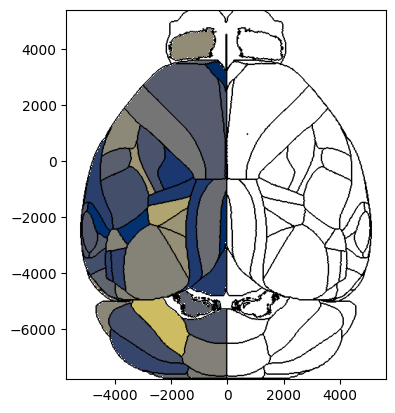

In [60]:
# import ibllib atlas module
from iblatlas.plots import plot_scalar_on_slice
from iblatlas.atlas import AllenAtlas
import numpy as np
ba = AllenAtlas()



# plot coronal slice at -2000 um from bregma
fig, axs = plot_scalar_on_slice(df.region.values, df.variability.values, coord=-2000, slice='top', background='boundary', cmap='cividis', ba=ba,mapping='Beryl',vmin = 0.2,vmax = .5)


In [17]:
df.region.values

array(['HPF', 'HPF', 'HPF', ..., 'root', 'root', 'root'], dtype=object)

In [16]:
df.region.unique()

array(['HPF', 'Isocortex', 'MB', 'root', 'void', 'TH', 'CNU', 'HY', 'HB'],
      dtype=object)